# Space Science — from the Moon to the outer solar system

Once a vehicle escapes the atmosphere, navigation becomes orbital mechanics:
*where are the planets, and what is the cheapest path between them?*  This notebook
builds from the simplest analytic model (a two-impulse Hohmann transfer) up to a
full N-body EKF-tracked cruise with real-time trajectory correction.

| Section | Topic | Key API |
|---------|-------|---------|
| 1 | Trans-lunar coast — Earth ↔ Moon | `TransLunarModel`, `lunar_porkchop` |
| 2 | Earth → Mars: Hohmann → porkchop → N-body EKF | `hohmann_transfer`, `porkchop`, `InterplanetaryModel` |
| 2d | Mid-course TCM — trajectory correction | `InterplanetaryModel(control=True)` |
| 3 | Earth → Jupiter: same framework, longer cruise | `InterplanetaryModel`, `porkchop` |
| 4 | Gravity assist: Jupiter→Saturn slingshot | `gravity_assist`, `hohmann_sequence`, `flyby_porkchop` |
| 5 | Second TCM from EKF covariance at 80 % TOF | EKF covariance → re-Lambert |
| 6 | Cassini VVEJGA: Earth→V→V→E→J→Saturn replication | `chain_lambert`, `plot_multi_leg` |

**Transfer methods used throughout:**

| Method | What it solves | Accuracy | When used |
|--------|---------------|----------|-----------|
| **Hohmann** | Two-impulse transfer between *circular, coplanar* orbits — analytic | Approximate | Quick Δv/TOF estimates |
| **Lambert** | Any two positions + time of flight, solved numerically | Exact (two-body) | Porkchop scan, trajectory seeds |
| **N-body EKF** | Lambert initial conditions propagated under Sun + planet perturbations, filtered | Realistic | Cruise simulation & navigation |

Ephemeris via astropy `builtin` (network-free JPL kernels).

In [1]:
%pip install numpy matplotlib astropy > /dev/null
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
np.seterr(all="ignore")

from kalman.apps.space import (TransLunarModel, InterplanetaryModel,
                               TrajectoryControlManeuver,
                               hohmann_transfer, lambert, porkchop, best_departure,
                               plot_solar_system, plot_porkchop,
                               gravity_assist, hohmann_sequence, flyby_porkchop,
                               plot_flyby_porkchop, plot_gravity_assist, plot_two_leg,
                               chain_lambert, plot_multi_leg,
                               lunar_porkchop, plot_porkchop)
from kalman.runtime.astro import (planet_positions, body_state, launch_site_state,
                                  R_EARTH, KM, D_MOON, GM_EARTH, GM_SUN, LU, DAY, D_SUN)
AU = D_SUN                    # 1 astronomical unit in Mm

Note: you may need to restart the kernel to use updated packages.


## 0 — The solar system, right now

`planet_positions()` returns the exact heliocentric position of every planet (and the Moon) at a
given time from the JPL-style `builtin` ephemeris — no download required.


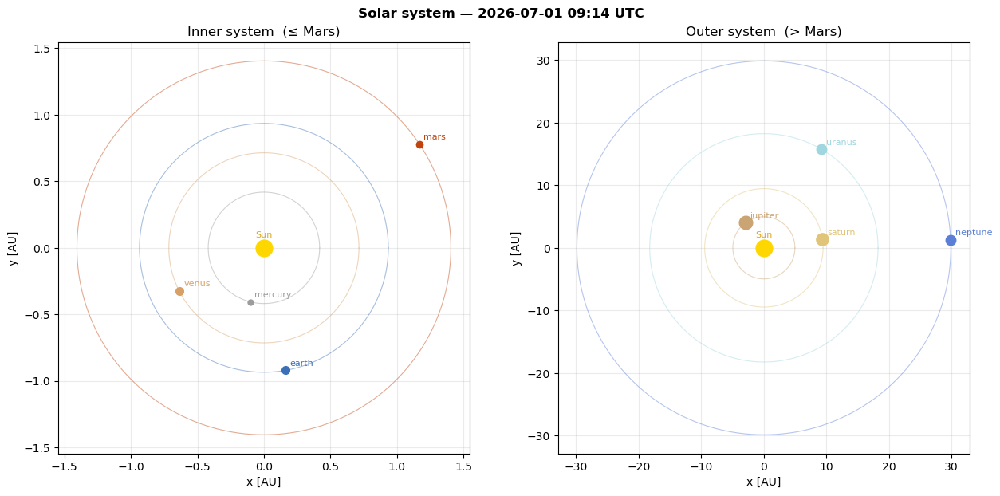

In [2]:
# Where is everything right now? Sun + planet orbits + live positions, to scale.
plot_solar_system(Time.now())
plt.show()

## 1 — Trans-lunar coast

A spacecraft coasting under **Earth + Moon + Sun** gravity on a free-return trajectory.
Injected onto a trans-lunar ellipse, it swings around the Moon and returns to Earth —
the Apollo geometry.  Only position is tracked (ground stations); the EKF reconstructs
full position + velocity from those three scalars per step.

The analytic model uses a circular Moon orbit; `use_ephemeris=True` (§ 1c) upgrades to
the exact JPL position and adds a launch-window scan (`lunar_porkchop`).


In [3]:
moon = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0, track_km=5.0, n_sub=4)
r0   = R_EARTH + 400 * KM                         # 400 km parking orbit
a_tx = 0.5 * (r0 + D_MOON)
v_tli = np.sqrt(GM_EARTH * (2.0 / r0 - 1.0 / a_tx)) + 0.034     # trans-lunar injection burn
x0 = np.array([[r0], [0], [0], [0], [v_tli], [0]])
P0 = np.diag([(50*KM)**2]*3 + [0.01**2]*3)

moon.initial_state(x0, P0=P0)
flight = moon.sample(7.5 * 86400.0 / 1000.0, process_noise=False)   # 7.5 days — full free-return
est    = moon.filter(flight.zk)

# Splashdown index: first re-entry (r < R_EARTH) after the lunar flyby
_r     = np.linalg.norm(np.asarray(flight.xk)[:, :3], axis=1)
_i_apo = int(_r[:int(4 * DAY / moon._dt)].argmax())   # apoapsis ≈ Moon flyby
splashdown_k = int(_i_apo + np.argmax(_r[_i_apo:] < R_EARTH))
print(f"Splashdown at t = {splashdown_k * moon._dt / DAY:.2f} d  (step {splashdown_k})")

# Earth-only twin (no Moon): the Keplerian counterfactual — where the craft drifts WITHOUT the
# lunar slingshot.  Sampled to half its period; the animation auto-extends to periapsis return.
kepler_twin = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0,
                              bodies=("earth",), n_sub=4)
kepler_twin.initial_state(x0, P0=P0)
kepler = kepler_twin.sample(10.5 * 86400.0 / 1000.0, process_noise=False)

moon.plot(est, sample=flight, interactive=True, frames=80, kepler=kepler, nmax=splashdown_k)


Splashdown at t = 6.65 d  (step 3191)


### 1c — Real Moon geometry (ephemeris) + trans-lunar launch window

`use_ephemeris=True` seeds the Moon/Sun phases from the real ephemeris at a chosen `epoch`,
instead of the illustrative analytic angles used above. Scanning departure dates with
`lunar_porkchop` (a geocentric Lambert scan against the Moon's exact position) finds the
monthly **trans-lunar injection (TLI) launch windows** — the lunar analogue of the
interplanetary porkchop in Section 2b.


In [4]:
moon_eph = TransLunarModel(dt_s=180.0, track_km=5.0, n_sub=4,
                           use_ephemeris=True, epoch="2026-11-06")
moon_eph.initial_state(x0, P0=P0)                      # same parking-orbit injection as Section 1
flight_eph = moon_eph.sample(5.5 * 86400.0 / 1000.0, process_noise=False)
est_eph    = moon_eph.filter(flight_eph.zk)
moon_eph.plot(est_eph, sample=flight_eph, interactive=True)
plt.show()


best TLI window: 2026-12-27 | tof 5.0 d | Δv_TLI 3.08 km/s  Δv_LOI 0.82 km/s


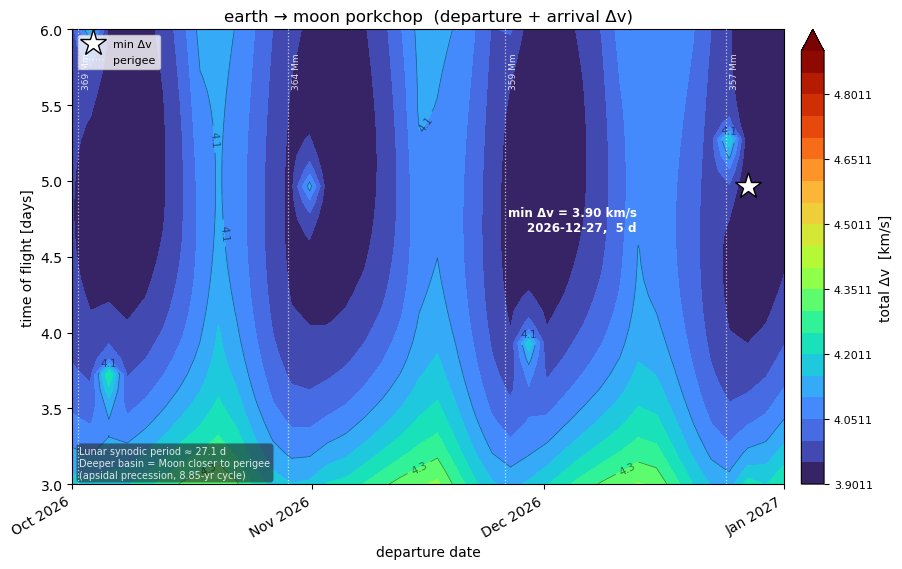

In [5]:
from kalman.apps.space import lunar_porkchop
lunar_grid = lunar_porkchop(start="2026-10-01", end="2027-01-01", n_dep=40, tof_days=(3, 6), n_tof=30)
lbest = lunar_grid["best"]
print("best TLI window:", lbest["dep_date"].iso[:10],
      "| tof %.1f d | \u0394v_TLI %.2f km/s  \u0394v_LOI %.2f km/s"
      % (lbest["tof_days"], lbest["dv_depart_kms"], lbest["dv_arrive_kms"]))
plot_porkchop(lunar_grid)
plt.show()


#### Why do successive basins get deeper?

Each **basin** is one monthly TLI window — the Moon completes one orbit every
**29.5 synodic days** (white dotted lines).  The deepening follows from the **8.85-year
apsidal precession** of the Moon's orbit (eccentricity ≈ 0.055): in late 2026 the
perigee is approaching a distance minimum, so each successive window finds a closer Moon:

| Perigee | Distance | TLI Δv |
|---------|----------|--------|
| Oct 02  | 369 300 km | shallowest |
| Oct 29  | 364 400 km | ↓ |
| Nov 26  | 359 400 km | ↓ |
| **Dec 24** | **356 700 km** | **deepest** |

A closer Moon → shorter transfer-orbit semi-major axis → less TLI energy.  The optimum
sits at **Dec 27** (3 days *after* perigee) because at exact perigee the Moon moves
fastest, raising the LOI arrival cost; the combined TLI + LOI minimum is 3 days later.

The TOF at minimum shifts from ~3.5 d in October to ~5 d in November because the
synodic month (window spacing, 29.5 d) and the anomalistic month (perigee-to-perigee,
27.5 d) differ — so each window catches the Moon at a progressively later orbital phase.

## 2 — Earth → Mars: analytic first estimate (Hohmann)

The **Hohmann transfer** is the fuel-optimal two-impulse path between two *circular, coplanar*
orbits.  It gives three numbers immediately: departure Δv, arrival Δv, and time of flight.
These are the targets every real mission is designed around, even though real orbits are
elliptic and inclined, and a numerical Lambert solve (§ 2b) is always used in practice.

For Earth→Mars the Hohmann gives **~5.6 km/s** total Δv and a **~260-day** flight.
Earth and Mars must be in the right relative geometry; the wait for the next window is
the ~780-day **synodic period**.


In [6]:
h = hohmann_transfer("earth", "mars")
for k, v in h.items():
    print(f"{k:24s}: {v.iso[:16] if hasattr(v,'iso') else round(v,3) if isinstance(v,float) else v}")

departure               : earth
target                  : mars
r1_AU                   : 1.017
r2_AU                   : 1.443
dv_depart_kms           : 2.456
dv_arrive_kms           : 2.25
dv_total_kms            : 4.706
tof_days                : 248.998
phase_angle_deg         : 38.353
synodic_period_days     : 916.685
next_departure          : 2027-01-09 08:14


## 2b — Launch window: the porkchop scan (Lambert)

Real orbits are elliptic and inclined, so Hohmann is only an approximation.  **Lambert's
problem** finds the orbit connecting two arbitrary positions in a specified time of flight —
no coplanarity or circularity required.  Solving Lambert at every (departure date, TOF) node
of a grid produces the *porkchop plot*: contours of total Δv over the launch window.

The minimum-Δv node seeds the cruise: `best_departure` extracts it and builds the initial
state vector `x0 = [r_Earth, v_Lambert]` ready for the EKF integrator.

> **Lambert vs Hohmann:** Lambert is exact for two-body dynamics (Sun only).
> The N-body EKF below adds planetary perturbations on top.


best departure: 2026-10-28 | tof 311 d | Δv_depart 3.05 km/s  C3 9.3 km²/s²


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 86 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 86 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


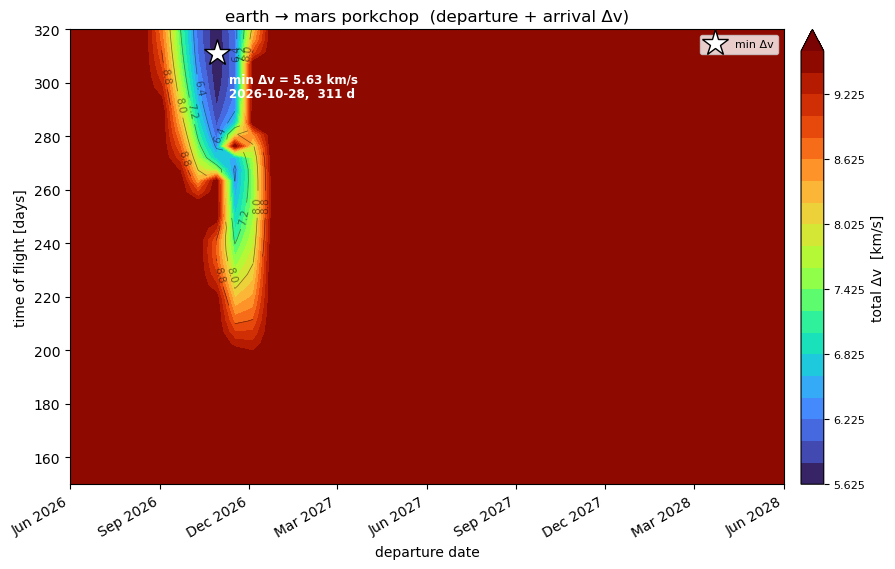

launch from Kennedy Space Center at 05:46 UTC  (Earth-rotation assist 0.364 km/s)


In [7]:
grid = porkchop("earth", "mars", start="2026-06-01", end="2028-06-01",
                n_dep=40, tof_days=(150, 320), n_tof=40)
best = grid["best"]
print("best departure:", best["dep_date"].iso[:10],
      "| tof %.0f d" % best["tof_days"],
      "| \u0394v_depart %.2f km/s  C3 %.1f km\u00b2/s\u00b2" % (best["dv_depart_kms"], best["c3_km2s2"]))

plot_porkchop(grid)
plt.show()

# Earth rotation: best time of day from a launch site (needs network for geocoding/IERS).
try:
    b2 = best_departure("earth", "mars", start="2026-06-01", end="2028-06-01",
                        n_dep=40, tof_days=(150, 320), n_tof=40, site="Kennedy Space Center")
    print("launch from %s at %s UTC  (Earth-rotation assist %.3f km/s)"
          % (b2["site"], b2["launch_time"].iso[11:16], b2["rotation_assist_kms"]))
except Exception as e:
    print("launch-site geocoding skipped (offline):", type(e).__name__)

## 2c — N-body EKF cruise: Earth → Mars

The Lambert initial state is propagated under **Sun + Venus + Jupiter + Saturn** gravity
(N-body dynamics).  Only position is observed — deep-space tracking gives range/range-rate,
modelled here as three Cartesian DSN fixes — and the **EKF reconstructs velocity**.

Because Lambert is a *two-body* solution, the planetary perturbations slowly accumulate
an arrival error that grows over the cruise.  § 2d shows how a mid-course burn (TCM)
nulls that error before arrival.


In [8]:
tof = best["tof_days"]
cruise = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
cruise.initial_state(best["x0"].reshape(-1, 1), P0=np.diag([1.,1.,1., 1e-4,1e-4,1e-4]))
trip = cruise.sample(tof * DAY, process_noise=False)
est  = cruise.filter(trip.zk)
X, E = np.asarray(trip.xk), np.asarray(est.xk)
err  = np.linalg.norm(X[:, :3] - E[:, :3], axis=1)
print("EKF mean position error: %.1f km  (final %.1f km)" % (err.mean()*1e3, err[-1]*1e3))
print("perturbing bodies:", cruise._field.bodies)
cruise.plot(est, sample=trip, interactive=True, frames=80)     # interactive cruise replay


EKF mean position error: 15.7 km  (final 4.1 km)
perturbing bodies: ('mercury', 'venus', 'jupiter', 'saturn')


## 2d — Mid-course Trajectory Correction Manoeuvres (TCMs)

Real interplanetary missions execute a **canonical TCM schedule**:

| TCM | Epoch | Purpose |
|-----|-------|---------|
| TCM-1 | day 5 | Dominant correction — fixes launch-injection error with *maximum leverage* |
| TCM-2 | day 30 | Mid-course trim of residual N-body drift |
| TCM-3 | day 90 | Optional fine-tune; often ≪ 1 m/s |

**Why early burns are most effective (the leverage principle):**  a Δv of 1 m/s applied
175 days before Mars shifts the arrival point by

$$\Delta r_{\rm arr} \approx \Delta v \times t_{\rm rem} = 1\,\text{m/s} \times 175\,\text{d} \times 86400\,\text{s/d} \approx 15\,100\,\text{km}$$

The same burn fired 5 days out moves the arrival by only **430 km**.  This is why TCM-1
almost always carries the bulk of the mission's correction budget.

**`TrajectoryControlManeuver`** — a `KalmanController` subclass — automates this:

1. At each scheduled epoch it **re-solves Lambert** from the current EKF position to Mars
   at arrival, finding the velocity needed.
2. Computes `Δv = v_needed − v_current` and caps it at `max_dv_kms` (50 m/s).
3. Applies the **Tsiolkovsky rocket equation** to derive propellant consumed and the
   **finite burn duration** (seconds to minutes — not an instantaneous kick).
4. Returns the velocity impulse; the EKF applies it as a prediction-step control input.

Spacecraft parameters (MRO / InSight class): 600 kg dry, 1200 kg wet, Isp 220 s,
thrust 22 N (hydrazine monoprop thrusters — small correction burns, not the main engine).

In [9]:
from astropy.time import TimeDelta
from kalman.framework.io.record import KalmanRecord

mc = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                         dt_s=43200.0, control=True, track_Mm=0.02)
dt = mc._dt; N = int(round(tof * DAY / dt))
arrival  = best["dep_date"] + TimeDelta(N * dt * 1000.0, format="sec")
mars_arr = body_state("mars", arrival)[0]

# ── Realistic injection error: ±2 m/s per axis (~3.5 m/s total 3-D) ──────
# Real TCMs correct launch-injection errors of 5–30 m/s (MRO TCM-1 = 18.5 m/s).
# ±2 m/s per axis is conservative/optimistic; the leverage physics still shows clearly.
rng = np.random.default_rng(7)
inj = np.r_[np.zeros(3), rng.normal(0, 0.002, 3)]   # km/s (~2 m/s each axis)
x0  = best["x0"] + inj
print("Injection error: %.1f m/s  (3-D)" % (np.linalg.norm(inj[3:]) * 1e3))
print("Heliocentric departure speed: %.2f km/s  "
      "(Earth ~29.8 km/s → +%.2f km/s from TLI)"
      % (np.linalg.norm(x0[3:]), np.linalg.norm(x0[3:]) - 29.8))
print("Spacecraft: %.0f kg dry / %.0f kg wet   Isp 220 s   thrust 22 N"
      % (mc.SPACECRAFT_DRY_MASS_KG, mc.SPACECRAFT_WET_MASS_KG))
print()

# ── TrajectoryControlManeuver — Lambert targeting + Tsiolkovsky burns ──────
# Pass the spacecraft parameters from the model constants (can override per mission).
tcm = TrajectoryControlManeuver(
    mc, mars_arr, N * dt,
    tcm_days=[5.0, 30.0, 90.0],              # canonical schedule: early burns dominate
    dry_mass_kg=mc.SPACECRAFT_DRY_MASS_KG,
    wet_mass_kg=mc.SPACECRAFT_WET_MASS_KG,
    Isp_s=220.0, thrust_N=22.0,
    max_dv_kms=0.050,                         # 50 m/s cap — real TCMs rarely exceed this
)

# ── Propagate truth WITH TCM burns (planning / autopilot pass) ────────────
def autopilot(x0, tcm_ctrl):
    """N-body truth propagation with TCM burns applied at scheduled epochs."""
    x = np.asarray(x0, float).ravel().copy()
    hist = [x.copy()]; P_nav = np.eye(6)
    for i in range(N):
        u = tcm_ctrl._policy(x.reshape(-1, 1), P_nav, i * dt)
        x = mc.f(x, u=(u if np.any(u != 0) else None), t=i * dt).ravel()
        hist.append(x.copy())
    return np.array(hist)

hist_cor = autopilot(x0, tcm)

# No-TCM open-loop truth (for counterfactual plot)
mc_nb = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
mc_nb.initial_state(x0.reshape(-1, 1))
trip_nom = mc_nb.sample(N * dt, process_noise=False)
hist_nom = np.asarray(trip_nom.xk)

miss_nom = np.linalg.norm(hist_nom[-1, :3]  - mars_arr) * 1e3   # km
miss_cor = np.linalg.norm(hist_cor[-1, :3]  - mars_arr) * 1e3
print("Arrival miss WITHOUT TCMs: %8.0f km  (%.3f AU)" % (miss_nom, miss_nom / (AU * 1e3)))
print("Arrival miss WITH TCMs   : %8.0f km" % miss_cor)
print()
tcm.summary()

Injection error: 0.8 m/s  (3-D)
Heliocentric departure speed: 32.97 km/s  (Earth ~29.8 km/s → +3.17 km/s from TLI)
Spacecraft: 600 kg dry / 1200 kg wet   Isp 220 s   thrust 22 N

Arrival miss WITHOUT TCMs:  1047417 km  (0.007 AU)
Arrival miss WITH TCMs   :    22114 km

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=    4.42 m/s  burn= 240.9 s  Δm=  2.46 kg  m_after=1197.54 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=    0.43 m/s  burn=  23.3 s  Δm=  0.24 kg  m_after=1197.31 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=    0.42 m/s  burn=  23.1 s  Δm=  0.24 kg  m_after=1197.07 kg  TOF_rem=  222 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=    5.27 m/s   Δm=  2.93 kg   propellant left: 597.07 kg


### Visualising the corrections

The EKF runs **closed-loop**: it receives noisy DSN fixes from the truth trajectory (with
TCM burns), and the `TrajectoryControlManeuver` controller re-solves Lambert at each
scheduled epoch to compute Δv from the EKF estimate.  The filter's burns may differ
slightly from the truth-pass burns because the EKF estimate ≠ truth (navigation noise).

Static overview: departure, each TCM event (×), and Mars arrival.
Interactive replay: orange Δv arrows flash on the exact burn frame; grey dashed line
shows the uncorrected counterfactual; the gravity readout updates each step.

EKF mean position error: 54403.9 km  (final 90179.9 km)

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=   30.69 m/s  burn=1662.2 s  Δm= 16.95 kg  m_after=1183.05 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=   32.21 m/s  burn=1719.4 s  Δm= 17.53 kg  m_after=1165.52 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=   44.85 m/s  burn=2351.4 s  Δm= 23.98 kg  m_after=1141.54 kg  TOF_rem=  222 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=  107.75 m/s   Δm= 58.46 kg   propellant left: 541.54 kg


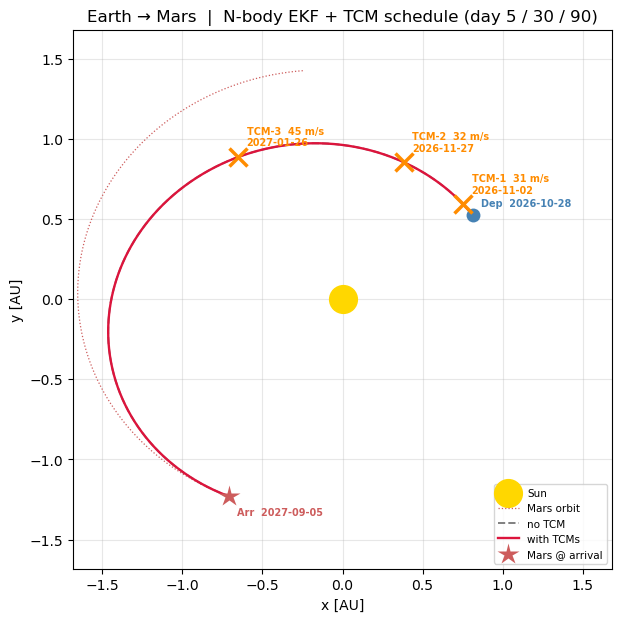

In [10]:
from astropy.time import TimeDelta as _TD

# ── Run closed-loop EKF with TCM controller ───────────────────────────────
# Reset restores full tanks + clears the fired set so the controller
# re-computes burns from the EKF estimate (rather than the truth-pass state).
tcm.reset()
trip_mc = KalmanRecord(xk=hist_cor, zk=hist_cor[:, :3])
mc.initial_state(x0.reshape(-1, 1), P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
est_mc = mc.filter(trip_mc.zk, uk=tcm)

err_mc = np.linalg.norm(
    np.asarray(est_mc.xk)[:, :3] - np.asarray(trip_mc.xk)[:, :3], axis=1)
print("EKF mean position error: %.1f km  (final %.1f km)" % (err_mc.mean()*1e3, err_mc[-1]*1e3))
print()
tcm.summary()   # burns computed from EKF estimate

# ── Static heliocentric overview ──────────────────────────────────────────
t_dep_str = best["dep_date"].iso[:10]
t_arr_str = arrival.iso[:10]

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0], [0], "o", color="gold", ms=20, label="Sun")
mars_trk = mc.planet_track("mars", N + 1) / AU
ax.plot(mars_trk[:, 0], mars_trk[:, 1], ":", color="indianred", lw=0.9, label="Mars orbit")
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, "--", color="0.5", lw=1.4, label="no TCM")
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color="crimson", lw=1.7, label="with TCMs")
dp = hist_cor[0, :2] / AU
ax.plot([dp[0]], [dp[1]], "o", color="steelblue", ms=10, mec="none", zorder=5)
ax.annotate(f"Dep  {t_dep_str}", dp, xytext=(6, 6), textcoords="offset points",
            fontsize=7, color="steelblue", fontweight="bold")
for b in tcm.burns:
    k_b = int(round(b["t_ks"] / dt))
    bp  = hist_cor[k_b, :2] / AU
    t_s = (best["dep_date"] + _TD(float(b["t_ks"]) * 1e3, format="sec")).iso[:10]
    ax.plot([bp[0]], [bp[1]], "x", color="darkorange", ms=13, mew=2.5, zorder=6)
    ax.annotate("TCM-%d  %.0f m/s\n%s" % (b["tcm_idx"], b["dv_ms"], t_s),
                bp, xytext=(6, 8), textcoords="offset points",
                fontsize=7, color="darkorange", fontweight="bold")
mp = mars_arr[:2] / AU
ax.plot([mp[0]], [mp[1]], "*", color="indianred", ms=16, mec="none", zorder=5, label="Mars @ arrival")
ax.annotate(f"Arr  {t_arr_str}", mp, xytext=(6, -14), textcoords="offset points",
            fontsize=7, color="indianred", fontweight="bold")
lim = 1.15 * np.abs(hist_cor[:, :2] / AU).max()
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_aspect("equal", adjustable="box"); ax.autoscale(False)
ax.set_xlabel("x [AU]"); ax.set_ylabel("y [AU]"); ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=7.5)
ax.set_title("Earth → Mars  |  N-body EKF + TCM schedule (day 5 / 30 / 90)")
plt.show()

# ── Interactive EKF replay ────────────────────────────────────────────────
burns_for_plot = [(int(round(b["t_ks"] / dt)), b["dv_vec_kms"]) for b in tcm.burns]
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=80,
        burns=burns_for_plot, no_burn=trip_nom)

## 3 — Earth → Jupiter: scaling to the outer solar system

Jupiter is 5.2 AU out (vs Mars at 1.5 AU), so the cruise lasts **2–3 years** and Saturn's
gravitational pull is now a measurable third-body perturbation alongside the inner planets.
Otherwise the pipeline is identical: Hohmann estimate → Lambert porkchop → N-body EKF.

One difference worth noting: the synodic period for Jupiter is **398 days** (just over a year),
so launch windows repeat almost annually, unlike the ~26-month Mars cycle.


Earth -> Jupiter Hohmann:  Δv_total 14.31 km/s   TOF 1019 days   synodic period 409 days
best E->J departure: 2028-12-12 | tof 1010 d | Δv_total 14.73 km/s


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 16 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 16 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133:

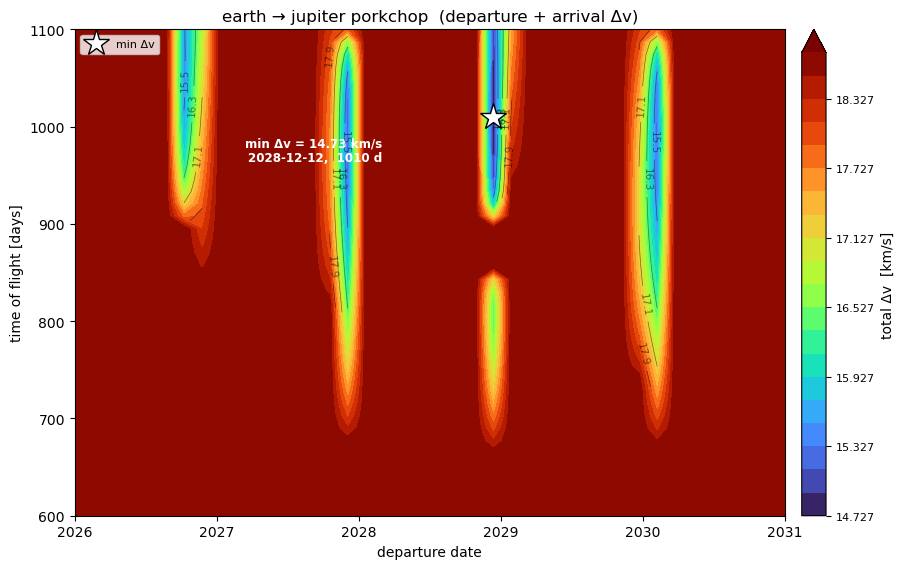

In [11]:
h_jup = hohmann_transfer("earth", "jupiter")
print("Earth -> Jupiter Hohmann:  \u0394v_total %.2f km/s   TOF %.0f days   synodic period %.0f days"
      % (h_jup["dv_total_kms"], h_jup["tof_days"], h_jup["synodic_period_days"]))

grid_jup = porkchop("earth", "jupiter", start="2026-01-01", end="2031-01-01",
                    n_dep=40, tof_days=(600, 1100), n_tof=40)
best_jup = grid_jup["best"]
print("best E->J departure:", best_jup["dep_date"].iso[:10],
      "| tof %.0f d | \u0394v_total %.2f km/s" % (best_jup["tof_days"], best_jup["dv_total_kms"]))
plot_porkchop(grid_jup)
plt.show()


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 527 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 527 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


EKF mean position error: 9189 km  (final 2164 km)
perturbing bodies: ('mercury', 'venus', 'mars', 'saturn')


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 991 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 991 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


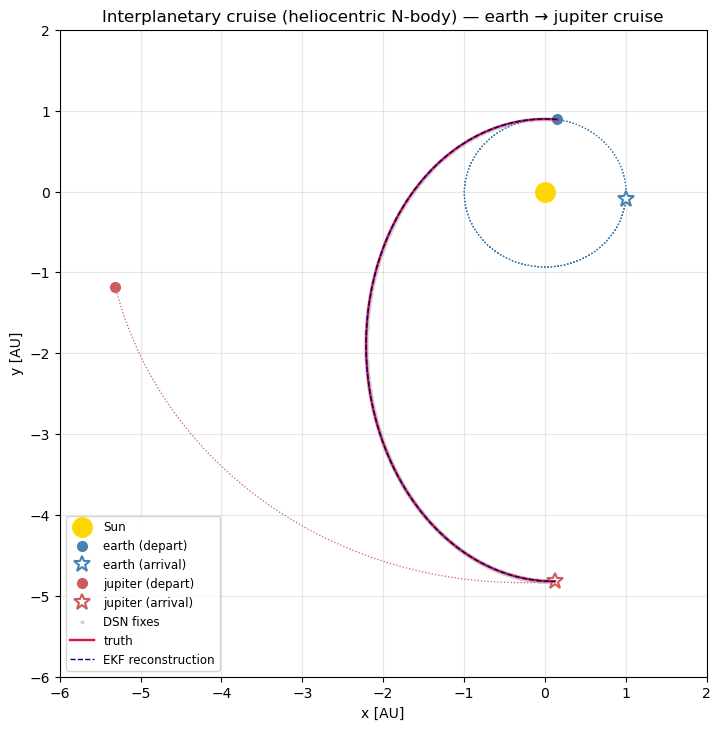

/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [12]:
cruise_jup = InterplanetaryModel('earth', 'jupiter', epoch=best_jup['dep_date'],
                                 span_days=best_jup['tof_days'] + 60,
                                 perturbers=('mercury', 'venus', 'mars', 'saturn'),
                                 dt_s=86400.0, track_Mm=0.5)
cruise_jup.initial_state(best_jup['x0'].reshape(-1, 1),
                         P0=np.diag([1., 1., 1., 1e-4, 1e-4, 1e-4]))
trip_jup = cruise_jup.sample(best_jup['tof_days'] * DAY, process_noise=False)
est_jup  = cruise_jup.filter(trip_jup.zk)
err_jup  = np.linalg.norm(
    np.asarray(trip_jup.xk)[:, :3] - np.asarray(est_jup.xk)[:, :3], axis=1)
print('EKF mean position error: %.0f km  (final %.0f km)' % (err_jup.mean()*1e3, err_jup[-1]*1e3))
print('perturbing bodies:', cruise_jup._field.bodies)

# Static overview
cruise_jup.plot(est_jup, sample=trip_jup, xlim=(-6, 2), ylim=(-6, 2))
plt.show()

# Interactive EKF replay (below)
cruise_jup.plot(est_jup, sample=trip_jup, interactive=True, frames=80)


## 4 — Gravity assist: Jupiter as a stepping stone to Saturn

A direct Hohmann from Earth to Saturn costs **15.6 km/s** and takes 6 years.  Chaining
two legs through a **free Jupiter flyby** — letting Jupiter's gravity turn and accelerate
the spacecraft for free — drops the total to **~10 km/s**, the same trick Voyager 1 & 2
and Cassini exploited.

### 4a — Analytic estimate: Hohmann chain

`hohmann_sequence(["earth","jupiter","saturn"])` strings together two analytic Hohmann arcs.
Each leg is treated as circular and coplanar; the flyby is patched-conic (hyperbolic approach
at Jupiter, then a new heliocentric Hohmann departs).  This gives a quick Δv lower bound;
the real optimum needs a Lambert scan (§ 4c).


In [13]:
from kalman.apps.space import gravity_assist, hohmann_sequence, flyby_porkchop, plot_flyby_porkchop

# --- Analytic Hohmann chain: departure burn + free Jupiter flyby + Saturn arrival ---
hs = hohmann_sequence(["earth", "jupiter", "saturn"])
print(f"Direct Earth→Saturn Hohmann :  Δv = {hs['dv_direct_kms']:.2f} km/s")
print(f"Earth→Jupiter→Saturn (free flyby): Δv = {hs['dv_total_kms']:.2f} km/s  "
      f"tof = {hs['tof_days']:.0f} d")
for leg in hs["legs"]:
    print(f"  {leg['departure']:8s} → {leg['target']:8s}: "
          f"Δv_dep={leg['dv_depart_kms']:.2f} km/s  "
          f"Δv_arr={leg['dv_arrive_kms']:.2f} km/s  "
          f"tof={leg['tof_days']:.0f} d")


Direct Earth→Saturn Hohmann :  Δv = 15.58 km/s
Earth→Jupiter→Saturn (free flyby): Δv = 10.20 km/s  tof = 4673 d
  earth    → jupiter : Δv_dep=8.71 km/s  Δv_arr=5.60 km/s  tof=1019 d
  jupiter  → saturn  : Δv_dep=1.73 km/s  Δv_arr=1.49 km/s  tof=3654 d


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


### 4b — The slingshot geometry at Jupiter

In Jupiter's rest frame the spacecraft arrives on a hyperbolic trajectory, curves around
Jupiter, and leaves at the same *speed* — but in the heliocentric frame it has gained
Jupiter's orbital velocity component along its new direction.  The key parameters are:

- **v_∞** — hyperbolic excess speed (spacecraft speed relative to Jupiter at infinity)
- **periapsis altitude** h — closer flyby = larger turn angle δ = 2 arcsin(μ_J / (μ_J + r_p v_∞²))
- **heliocentric Δv** — can reach several km/s for a Jupiter flyby

The calculation below uses `gravity_assist()` with the Lambert-derived arrival v_∞ and
a 500 km periapsis, then computes the patched-conic departure velocity.


In [14]:
# Simplified 1-D geometry: Earth→Jupiter Hohmann speed at Jupiter orbit
R_J = np.linalg.norm(body_state('jupiter')[0])
R_E = np.linalg.norm(body_state('earth')[0])
a_EJ = 0.5 * (R_E + R_J)
v_trans_at_J = float(np.sqrt(GM_SUN * (2 / R_J - 1 / a_EJ)))
v_jup_circ   = float(np.sqrt(GM_SUN / R_J))

ga = gravity_assist(
    v_in_helio     = np.array([v_trans_at_J, 0., 0.]),
    v_planet_helio = np.array([v_jup_circ,   0., 0.]),
    planet         = 'jupiter',
    h_periapsis_km = 500.0,
)
print(f"Approach v_inf           : {ga['v_inf_mag']:.2f} km/s")
print(f"Max turn angle (h=500 km): {ga['turn_angle_deg']:.0f}°")
print(f"Heliocentric speed: {ga['v_helio_in']:.2f} → {ga['v_helio_out']:.2f} km/s  "
      f"(Δv_gain = +{ga['dv_gain_kms']:.2f} km/s)")

plot_gravity_assist(ga, planet='jupiter')


Approach v_inf           : 5.60 km/s
Max turn angle (h=500 km): 159°
Heliocentric speed: 7.37 → 18.30 km/s  (Δv_gain = +10.93 km/s)


### 4c — Two-leg porkchop: Earth → Jupiter → Saturn

`flyby_porkchop` solves two Lambert arcs at every (tof₁, tof₂) grid node and checks the
patched-conic flyby constraint at Jupiter: the required turn angle must be achievable at
the chosen periapsis altitude.  Infeasible nodes are masked.

Unlike the Hohmann chain (§ 4a), this uses **real ephemeris positions**, so it captures
orbital eccentricity, inclination, and the actual Jupiter–Saturn alignment in the chosen
window.  The minimum-Δv node (★) seeds the two-leg interactive trajectory below.


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 30 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 30 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 900 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 900 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py

Best E→J→S trajectory (fixed dep 2028-12-12):
  tof₁=1014 d  tof₂=1600 d
  Δv_dep=9.03  Δv_flyby=0.864  Δv_arr=10.36  total=20.26 km/s


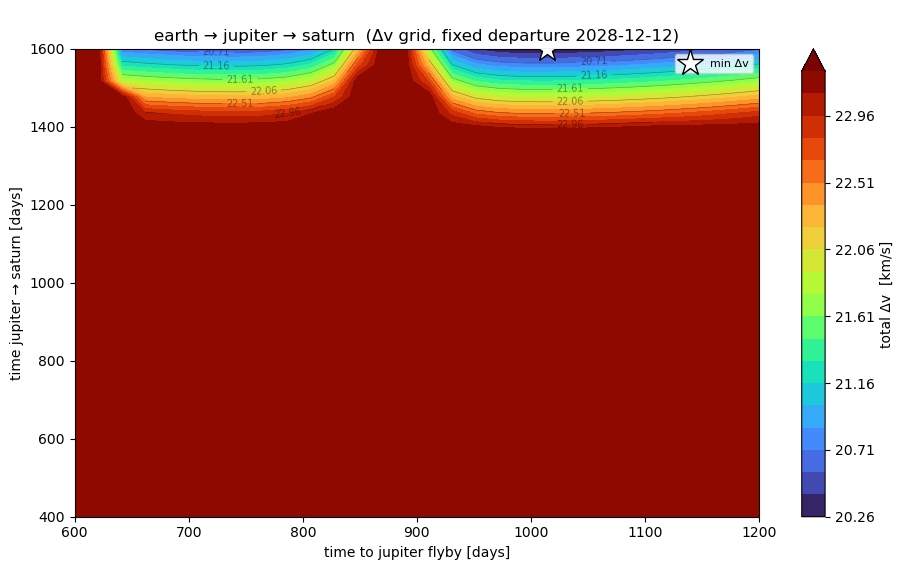

In [15]:
flyby_grid = flyby_porkchop(
    "earth", "jupiter", "saturn", best_jup["dep_date"],
    tof1_range=(600, 1200), tof2_range=(400, 1600),
    n_tof1=30, n_tof2=30, h_min_km=500.0,
)
b2 = flyby_grid["best"]
print(f"Best E→J→S trajectory (fixed dep {b2['dep_date'].iso[:10]}):")
print(f"  tof₁={b2['tof1_days']:.0f} d  tof₂={b2['tof2_days']:.0f} d")
print(f"  Δv_dep={b2['dv_depart_kms']:.2f}  Δv_flyby={b2['dv_flyby_kms']:.3f}  "
      f"Δv_arr={b2['dv_arrive_kms']:.2f}  total={b2['dv_total_kms']:.2f} km/s")
plot_flyby_porkchop(flyby_grid)
plt.show()


### 4d — Two-leg trajectory  *(interactive)*

Both legs are **Lambert arcs** seeded from real ephemeris positions at the best
(tof₁, tof₂) node.  Use the slider to follow the spacecraft through the Jupiter flyby
and on to Saturn.


In [16]:
plot_two_leg(b2)


/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


## 5 — Propellant budget, burn physics and EKF uncertainty

The `TrajectoryControlManeuver` tracks propellant consumption via the **Tsiolkovsky
rocket equation**:

$$m_{\rm after} = m_{\rm before} \cdot e^{-\Delta v / (I_{\rm sp}\,g_0)}$$

$$t_{\rm burn} = \frac{\Delta m \cdot I_{\rm sp} \cdot g_0}{F_{\rm thrust}}$$

With Isp = 220 s and thrust = 22 N, even a 10 m/s burn only lasts ~60 s and consumes
~6 kg — a tiny fraction of the 600 kg propellant reserve.  This is typical: real TCMs
are propellant-cheap compared to the main orbit insertion burn (MRO's MOI used ~900 kg).

The right panel shows EKF position uncertainty σ_r over the cruise.  Each TCM fires into
the uncertainty so the filter is correcting slightly different from the truth-pass burns.
The covariance *drop after each TCM* is small because the burns are small — the filter's
uncertainty is driven mostly by DSN tracking noise, not burn magnitude.

In [17]:
print("Propellant budget for this mission")
print("─" * 52)
print("  Spacecraft dry mass : %6.0f kg" % tcm.dry_mass)
print("  Launch wet mass     : %6.0f kg" % tcm._wet_mass_init)
print("  Total propellant    : %6.0f kg" % (tcm._wet_mass_init - tcm.dry_mass))
print()
for b in tcm.burns:
    dv_leverage_km = b["dv_ms"] * 1e-3 * b["tof_rem_days"] * 86400.0 / 1e6   # Mm
    print("  TCM-%-2d  t=%5.1f d  Δv=%6.2f m/s  burn=%5.1f s  "
          "Δm=%5.2f kg  arrival leverage ≈ %.0f km"
          % (b["tcm_idx"], b["t_days"], b["dv_ms"], b["burn_s"],
             b["prop_kg"], dv_leverage_km * 1e3))
print()
print("  Total TCM Δv        : %6.2f m/s" % sum(b["dv_ms"] for b in tcm.burns))
print("  Total Δm consumed   : %6.2f kg  (%.2f %% of propellant)"
      % (tcm.propellant_consumed_kg,
         100.0 * tcm.propellant_consumed_kg / max(tcm._wet_mass_init - tcm.dry_mass, 1)))
print("  Propellant remaining: %6.2f kg  (reserved for Mars Orbit Insertion)"
      % tcm.propellant_remaining_kg)
print()
print("Reference:  MRO TCM-1 = 18.5 m/s (~12 kg),  MSL TCM-1 = 5.0 m/s (~3 kg)")

Propellant budget for this mission
────────────────────────────────────────────────────
  Spacecraft dry mass :    600 kg
  Launch wet mass     :   1200 kg
  Total propellant    :    600 kg

  TCM-1   t=  5.0 d  Δv= 30.69 m/s  burn=1662.2 s  Δm=16.95 kg  arrival leverage ≈ 813 km
  TCM-2   t= 30.0 d  Δv= 32.21 m/s  burn=1719.4 s  Δm=17.53 kg  arrival leverage ≈ 783 km
  TCM-3   t= 90.0 d  Δv= 44.85 m/s  burn=2351.4 s  Δm=23.98 kg  arrival leverage ≈ 858 km

  Total TCM Δv        : 107.75 m/s
  Total Δm consumed   :  58.46 kg  (9.74 % of propellant)
  Propellant remaining: 541.54 kg  (reserved for Mars Orbit Insertion)

Reference:  MRO TCM-1 = 18.5 m/s (~12 kg),  MSL TCM-1 = 5.0 m/s (~3 kg)


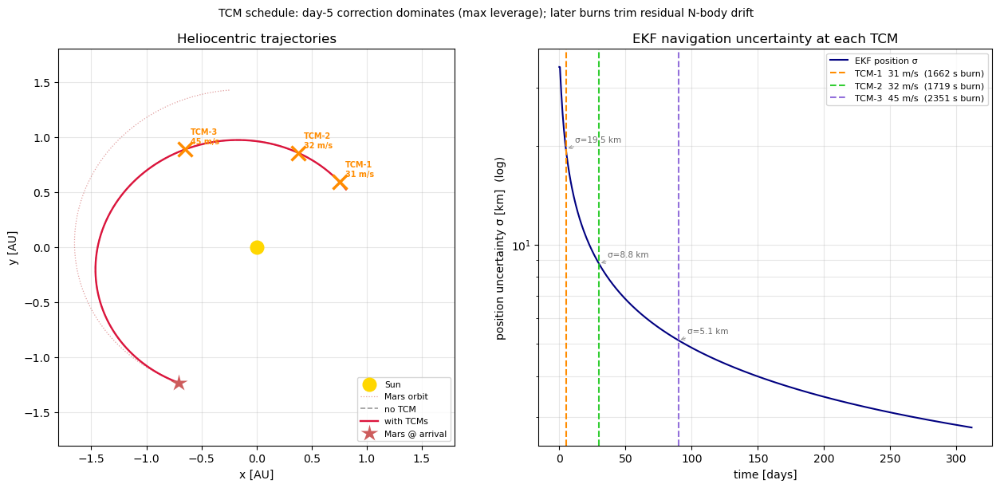

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))

# ── Left: heliocentric overview with all TCM events ──────────────────────
ax = axes[0]
mars_trk2 = mc.planet_track("mars", len(hist_cor)) / AU
ax.plot([0], [0], "o", color="gold", ms=12, zorder=6, label="Sun")
ax.plot(mars_trk2[:, 0], mars_trk2[:, 1], ":", color="indianred", lw=0.9, alpha=0.6, label="Mars orbit")
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, "--", color="0.6", lw=1.2, label="no TCM")
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color="crimson", lw=1.7, label="with TCMs")
for b in tcm.burns:
    k_b = int(round(b["t_ks"] / dt))
    bp  = hist_cor[k_b, :2] / AU
    ax.plot([bp[0]], [bp[1]], "x", color="darkorange", ms=13, mew=2.5, zorder=6)
    ax.annotate("TCM-%d\n%.0f m/s" % (b["tcm_idx"], b["dv_ms"]),
                bp, xytext=(5, 5), textcoords="offset points",
                fontsize=7, color="darkorange", fontweight="bold")
mars_pos = mars_arr[:2] / AU
ax.plot([mars_pos[0]], [mars_pos[1]], "*", color="indianred", ms=16, mec="none", zorder=5,
        label="Mars @ arrival")
ax.autoscale(False); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [AU]"); ax.set_ylabel("y [AU]")
ax.set_title("Heliocentric trajectories")
ax.legend(fontsize=7.8, loc="lower right"); ax.grid(alpha=0.3)

# ── Right: EKF position uncertainty + TCM timing ─────────────────────────
ax2 = axes[1]
Pk_all  = np.asarray(est_mc.Pk)
sigma_r = np.sqrt(np.trace(Pk_all[:, :3, :3], axis1=1, axis2=2)) * 1e3
t_days_all = np.arange(len(sigma_r)) * dt / DAY
ax2.semilogy(t_days_all, sigma_r, color="navy", lw=1.5, label="EKF position σ")
colors_tcm = ["darkorange", "limegreen", "mediumpurple"]
for b, col in zip(tcm.burns, colors_tcm):
    t_burn_d = b["t_days"]
    k_b = int(round(b["t_ks"] / dt))
    sigma_at_burn = float(sigma_r[min(k_b, len(sigma_r) - 1)])
    ax2.axvline(t_burn_d, color=col, ls="--", lw=1.5,
                label="TCM-%d  %.0f m/s  (%.0f s burn)"
                % (b["tcm_idx"], b["dv_ms"], b["burn_s"]))
    ax2.annotate("σ=%.1f km" % sigma_at_burn,
                 xy=(t_burn_d, sigma_at_burn),
                 xytext=(8, 6), textcoords="offset points",
                 fontsize=7.5, color="0.4",
                 arrowprops=dict(arrowstyle="->", color="0.6", lw=0.7))
ax2.set_xlabel("time [days]"); ax2.set_ylabel("position uncertainty σ [km]  (log)")
ax2.set_title("EKF navigation uncertainty at each TCM")
ax2.legend(fontsize=8.0); ax2.grid(alpha=0.3, which="both")

plt.suptitle("TCM schedule: day-5 correction dominates (max leverage); "
             "later burns trim residual N-body drift", fontsize=10)
plt.tight_layout(); plt.show()

# ── Interactive EKF replay with all burns ────────────────────────────────
burns_for_plot = [(int(round(b["t_ks"] / dt)), b["dv_vec_kms"]) for b in tcm.burns]
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=80,
        burns=burns_for_plot, no_burn=trip_nom)

## 6 — Cassini VVEJGA: replicating the Grand Tour

**Cassini–Huygens** (launched 15 October 1997) took **6 years 9 months** to reach Saturn,
using one of the most intricate gravity-assist sequences ever flown:

> Earth → Venus → Venus → Earth → Jupiter → Saturn

The route — **V**enus–**V**enus–**E**arth–**J**upiter **G**ravity **A**ssist (VVEJGA) —
made three trips around the inner solar system before departing for the outer system,
accumulating ~15 km/s of free Δv from planetary flybys:

| Leg | Departure | Arrival | TOF |
|-----|-----------|---------|-----|
| 1  | Earth     | Venus   | 1997-10-15 → 1998-04-26 | 193 d |
| 2  | Venus     | Venus   | 1998-04-26 → 1999-06-24 | 424 d |
| 3  | Venus     | Earth   | 1999-06-24 → 1999-08-18 |  55 d |
| 4  | Earth     | Jupiter | 1999-08-18 → 2000-12-30 | 500 d |
| 5  | Jupiter   | Saturn  | 2000-12-30 → 2004-07-01 | 1279 d |

`chain_lambert` solves five Lambert arcs (one per leg) using the actual historical flyby
dates, then `plot_multi_leg` animates the full trajectory from launch to Saturn orbit
insertion.  The patched-conic solver gives approximate Δv at each flyby node; the true
burns were ≲ 1 m/s correction manoeuvres — the planets did the real work.

In [ ]:
from astropy.time import Time
from kalman.apps.space import chain_lambert, plot_multi_leg

cassini_sequence = ["earth", "venus", "venus", "earth", "jupiter", "saturn"]
cassini_dates    = [
    Time("1997-10-15"),   # launch
    Time("1998-04-26"),   # Venus 1 flyby
    Time("1999-06-24"),   # Venus 2 flyby
    Time("1999-08-18"),   # Earth flyby
    Time("2000-12-30"),   # Jupiter flyby
    Time("2004-07-01"),   # Saturn orbit insertion
]

legs = chain_lambert(cassini_sequence, cassini_dates)

print("Cassini VVEJGA — Lambert solution per leg")
print(f"{'Leg':>3}  {'Route':>18}  {'TOF (d)':>8}  {'Δv_flyby (m/s)':>15}")
for i, lg in enumerate(legs):
    route = f"{lg['departure']}→{lg['arrival']}"
    print(f"{i+1:>3}  {route:>18}  {lg['tof_days']:>8.0f}  {lg['dv_flyby_kms']*1e3:>15.0f}")

total_tof = sum(lg["tof_days"] for lg in legs)
print(f"\nTotal mission time: {total_tof:.0f} days  ({total_tof/365.25:.1f} years)")

# Two-panel: LEFT = inner solar system (VVEJ flybys), RIGHT = full Earth→Saturn scale.
# zoom_lim="auto" sizes the left panel to the tightest box that fits all inner arcs
# (< 4 AU) without clipping; legs that exit the zoom box are suppressed there to avoid
# discontinuous line artefacts (e.g. the Earth→Jupiter leg clipping at x = 2.1 AU).
plot_multi_leg(legs,
               title="Cassini VVEJGA  (1997–2004)  —  Earth → Venus → Venus → Earth → Jupiter → Saturn",
               extra_planets=("mars",),
               frames=120,
               zoom_lim="auto")

Cassini VVEJGA — Lambert solution per leg
Leg               Route   TOF (d)   Δv_flyby (m/s)
  1         earth→venus       193                0
  2         venus→venus       424             4412
  3         venus→earth        55             3814
  4       earth→jupiter       500             5912
  5      jupiter→saturn      1279             1969

Total mission time: 2451 days  (6.7 years)


## Further reading

- **More complex gravity assists.**  Cassini used Venus–Venus–Earth–Jupiter (VVEJGA) to reach
  Saturn.  Try chaining `flyby_porkchop` calls or extending `hohmann_sequence` to four legs.
- **Autonomous optical navigation.**  Real probes update the EKF with star-tracker bearing
  measurements (angle-only).  Swap the DSN position model for an `H = angle` observation
  matrix and observe how the covariance grows differently.
- Back to the pad: **06 — Rocket Science** covers liftoff, guided ascent and the gimballed
  landing.
